In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [3]:
import os
import tarfile
import subprocess

url = "https://media.githubusercontent.com/media/vignagajan/CUB-200-2011/main/CUB_200_2011.tgz"
archive_path = "/content/CUB_200_2011.tgz"

if not os.path.exists("/content/CUB_200_2011/images"):
    subprocess.run(
        ["curl", "-L", "--fail", "-A", "Mozilla/5.0",
         url, "-o", archive_path],
        check=True
    )

    print("Downloaded size:", os.path.getsize(archive_path) / (1024**3), "GB")

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall("/content")

print("Dataset ready:", os.path.exists("/content/CUB_200_2011/images"))

Downloaded size: 1.0715661002323031 GB


/tmp/ipykernel_1032/3623965540.py:18: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/content")


Dataset ready: True


**Check the dataset files**

In [4]:
import os

ROOT = "/content/CUB_200_2011"

required_files = [
    "images.txt",
    "image_class_labels.txt",
    "bounding_boxes.txt",
    "train_test_split.txt",
    "classes.txt"
]

for file in required_files:
    path = os.path.join(ROOT, file)
    print(file, ":", "FOUND" if os.path.exists(path) else "MISSING")

print("Image folders:", len(os.listdir(os.path.join(ROOT, "images"))))

images.txt : FOUND
image_class_labels.txt : FOUND
bounding_boxes.txt : FOUND
train_test_split.txt : FOUND
classes.txt : FOUND
Image folders: 200


**Load the dataset annotations**

In [5]:
import pandas as pd
import os

images = pd.read_csv(
    f"{ROOT}/images.txt",
    sep=" ",
    header=None,
    names=["image_id", "filepath"]
)

labels = pd.read_csv(
    f"{ROOT}/image_class_labels.txt",
    sep=" ",
    header=None,
    names=["image_id", "label"]
)

boxes = pd.read_csv(
    f"{ROOT}/bounding_boxes.txt",
    sep=" ",
    header=None,
    names=["image_id", "x", "y", "w", "h"]
)

splits = pd.read_csv(
    f"{ROOT}/train_test_split.txt",
    sep=" ",
    header=None,
    names=["image_id", "is_train"]
)

df = images.merge(labels, on="image_id")
df = df.merge(boxes, on="image_id")
df = df.merge(splits, on="image_id")

df["label"] = df["label"] - 1
df["filepath"] = df["filepath"].apply(
    lambda p: os.path.join(ROOT, "images", p)
)

print("Total images:", len(df))
print("Number of species:", df["label"].nunique())
print("Training images:", (df["is_train"] == 1).sum())
print("Testing images:", (df["is_train"] == 0).sum())

display(df.head())

Total images: 11788
Number of species: 200
Training images: 5994
Testing images: 5794


,image_id,filepath,label,x,y,w,h,is_train
0,1,/content/CUB_200_2011/images/001.Black_footed_...,0,60.0,27.0,325.0,304.0,0
1,2,/content/CUB_200_2011/images/001.Black_footed_...,0,139.0,30.0,153.0,264.0,1
2,3,/content/CUB_200_2011/images/001.Black_footed_...,0,14.0,112.0,388.0,186.0,0
3,4,/content/CUB_200_2011/images/001.Black_footed_...,0,112.0,90.0,255.0,242.0,1
4,5,/content/CUB_200_2011/images/001.Black_footed_...,0,70.0,50.0,134.0,303.0,1


**Display the original image and cropped bird**

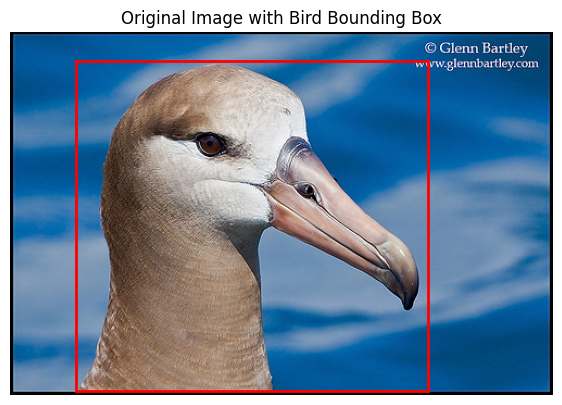

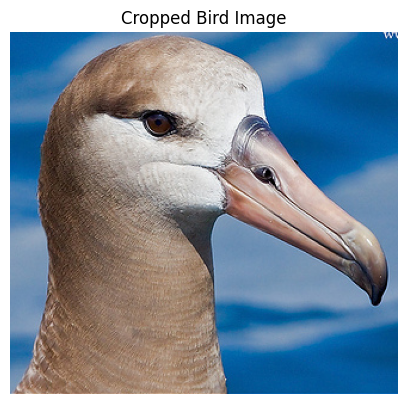

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

row = df.iloc[0]
img = Image.open(row["filepath"]).convert("RGB")

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(img)

rect = patches.Rectangle(
    (row["x"], row["y"]),
    row["w"],
    row["h"],
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)
ax.set_title("Original Image with Bird Bounding Box")
ax.axis("off")
plt.show()

x = max(0, int(row["x"]))
y = max(0, int(row["y"]))
right = min(img.width, int(row["x"] + row["w"]))
bottom = min(img.height, int(row["y"] + row["h"]))

cropped = img.crop((x, y, right, bottom))

plt.figure(figsize=(5, 5))
plt.imshow(cropped)
plt.title("Cropped Bird Image")
plt.axis("off")
plt.show()

**Prepare training and validation data**

In [7]:
from sklearn.model_selection import train_test_split

train_df = df[df["is_train"] == 1].copy()
test_df = df[df["is_train"] == 0].copy()

train_df, val_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=42,
    stratify=train_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 5094
Validation images: 900
Testing images: 5794


**Create the image-processing pipeline**

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class BirdDataset(Dataset):
    def __init__(self, data, crop=False, training=False):
        self.data = data.reset_index(drop=True)
        self.crop = crop
        self.transform = train_transform if training else eval_transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]
        image = Image.open(row["filepath"]).convert("RGB")

        if self.crop:
            x = max(0, int(row["x"]))
            y = max(0, int(row["y"]))
            right = min(image.width, int(row["x"] + row["w"]))
            bottom = min(image.height, int(row["y"] + row["h"]))
            image = image.crop((x, y, right, bottom))

        image = self.transform(image)
        label = int(row["label"])

        return image, label

def make_loaders(crop=False):
    return (
        DataLoader(
            BirdDataset(train_df, crop=crop, training=True),
            batch_size=32,
            shuffle=True,
            num_workers=2
        ),
        DataLoader(
            BirdDataset(val_df, crop=crop),
            batch_size=32,
            shuffle=False,
            num_workers=2
        ),
        DataLoader(
            BirdDataset(test_df, crop=crop),
            batch_size=32,
            shuffle=False,
            num_workers=2
        )
    )

print("Image-processing pipeline ready!")

Using device: cuda
Image-processing pipeline ready!


**Load the pretrained ResNet-18 CNN**

In [9]:
import torch.nn as nn
from torchvision import models

def create_model():
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, 200)
    return model.to(device)

model = create_model()

print("CNN model loaded successfully")
print("Number of output classes:", model.fc.out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 117MB/s]


CNN model loaded successfully
Number of output classes: 200
Device: cuda


**Train the model on original images**

In [12]:
import copy
import time
from tqdm.auto import tqdm

def train_model(crop=False, epochs=2):
    train_loader, val_loader, test_loader = make_loaders(crop)

    model = create_model()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.0001,
        weight_decay=0.0001
    )

    best_accuracy = 0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        correct = 0
        total = 0
        start = time.time()

        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1}"):
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_accuracy = correct / total
        model.eval()
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)
                outputs = model(images)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_accuracy = val_correct / val_total

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {running_loss / total:.4f} | "
            f"Train Accuracy: {train_accuracy * 100:.2f}% | "
            f"Validation Accuracy: {val_accuracy * 100:.2f}% | "
            f"Time: {time.time() - start:.1f}s"
        )

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, test_loader

print("Training function ready!")

Training function ready!


**Run the baseline experiment**

In [13]:
original_model, original_test_loader = train_model(
    crop=False,
    epochs=2
)

torch.save(
    original_model.state_dict(),
    "/content/bird_model_original.pth"
)

print("Original-image model training completed!")

Epoch 1:   0%|          | 0/160 [00:00<?, ?it/s]

Epoch 1/2 | Loss: 4.5368 | Train Accuracy: 14.43% | Validation Accuracy: 36.22% | Time: 32.5s


Epoch 2:   0%|          | 0/160 [00:00<?, ?it/s]

Epoch 2/2 | Loss: 2.9195 | Train Accuracy: 52.39% | Validation Accuracy: 50.44% | Time: 32.3s
Original-image model training completed!


**Improve the model before proceeding**

In [14]:
import torch
import torch.nn as nn

from tqdm.auto import tqdm

train_loader, val_loader, original_test_loader = make_loaders(crop=False)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    original_model.parameters(),
    lr=0.00005,
    weight_decay=0.0001
)

best_accuracy = 0.0
best_state = None

for epoch in range(3):
    original_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc=f"Extra Epoch {epoch + 1}"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = original_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_accuracy = correct / total

    original_model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = original_model(images)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    print(
        f"Extra Epoch {epoch + 1} | "
        f"Loss: {running_loss / total:.4f} | "
        f"Training Accuracy: {train_accuracy * 100:.2f}% | "
        f"Validation Accuracy: {val_accuracy * 100:.2f}%"
    )

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in original_model.state_dict().items()
        }

if best_state is not None:
    original_model.load_state_dict(best_state)

torch.save(original_model.state_dict(), "/content/bird_model_original.pth")

print("Improved original-image model saved.")

Extra Epoch 1:   0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Extra Epoch 1 | Loss: 1.9795 | Training Accuracy: 75.17% | Validation Accuracy: 60.67%


Extra Epoch 2:   0%|          | 0/160 [00:00<?, ?it/s]

Extra Epoch 2 | Loss: 1.4762 | Training Accuracy: 84.75% | Validation Accuracy: 63.67%


Extra Epoch 3:   0%|          | 0/160 [00:00<?, ?it/s]

Extra Epoch 3 | Loss: 1.1080 | Training Accuracy: 90.68% | Validation Accuracy: 65.00%
Improved original-image model saved.


**Train the cropped-image model**

In [15]:
import copy
import torch
import torch.nn as nn
from tqdm.auto import tqdm

train_loader, val_loader, cropped_test_loader = make_loaders(crop=True)

cropped_model = create_model()

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    cropped_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

best_accuracy = 0.0
best_state = None

for epoch in range(5):
    cropped_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader, desc=f"Crop Epoch {epoch + 1}"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = cropped_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_accuracy = correct / total

    cropped_model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cropped_model(images)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {running_loss / total:.4f} | "
        f"Train Accuracy: {train_accuracy * 100:.2f}% | "
        f"Validation Accuracy: {val_accuracy * 100:.2f}%"
    )

    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_state = copy.deepcopy(cropped_model.state_dict())

cropped_model.load_state_dict(best_state)

torch.save(
    cropped_model.state_dict(),
    "/content/bird_model_cropped.pth"
)

print("Best cropped-image model saved!")
print(f"Best validation accuracy: {best_accuracy * 100:.2f}%")

Crop Epoch 1:   0%|          | 0/160 [00:00<?, ?it/s]

Epoch 1/5 | Loss: 4.4161 | Train Accuracy: 17.75% | Validation Accuracy: 41.89%


Crop Epoch 2:   0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Epoch 2/5 | Loss: 2.6160 | Train Accuracy: 61.11% | Validation Accuracy: 59.89%


...

Crop Epoch 4:   0%|          | 0/160 [00:00<?, ?it/s]

Epoch 4/5 | Loss: 1.0213 | Train Accuracy: 89.05% | Validation Accuracy: 73.00%


Crop Epoch 5:   0%|          | 0/160 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>    
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Epoch 5/5 | Loss: 0.6304 | Train Accuracy: 94.52% | Validation Accuracy: 74.33%
Best cropped-image model saved!
Best validation accuracy: 74.33%


**Evaluate both models on the official test set**

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from tqdm.auto import tqdm
import pandas as pd
import torch

def evaluate_model(model, test_loader, name):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc=name):
            images = images.to(device)
            outputs = model(images)

            predictions = outputs.argmax(dim=1).cpu().tolist()

            y_pred.extend(predictions)
            y_true.extend(labels.tolist())

    return {
        "Experiment": name,
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision Macro (%)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "Recall Macro (%)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100,
        "F1 Macro (%)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ) * 100
    }

original_model.eval()
cropped_model.eval()

original_test_loader = make_loaders(crop=False)[2]
cropped_test_loader = make_loaders(crop=True)[2]

test_results = []

test_results.append(
    evaluate_model(
        original_model,
        original_test_loader,
        "Original Images"
    )
)

test_results.append(
    evaluate_model(
        cropped_model,
        cropped_test_loader,
        "Cropped Images"
    )
)

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(2))

test_results_df.to_csv(
    "/content/PS37_final_test_results.csv",
    index=False
)

print("Test results saved successfully!")

Original Images:   0%|          | 0/182 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>
Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d2b137258a0>
    Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__



Cropped Images:   0%|          | 0/182 [00:00<?, ?it/s]

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        
AssertionErrorassert self._parent_pid == os.getpid(), 'can only test a child process': 
can only test a child process
AssertionError: can only test a child process


,Experiment,Accuracy (%),Precision Macro (%),Recall Macro (%),F1 Macro (%)
0,Original Images,65.98,67.70,66.27,65.77
1,Cropped Images,76.49,77.91,76.60,76.21


Test results saved successfully!


**save your experiment results**

In [17]:
from google.colab import files
files.download("/content/PS37_final_test_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**GRAPHS**

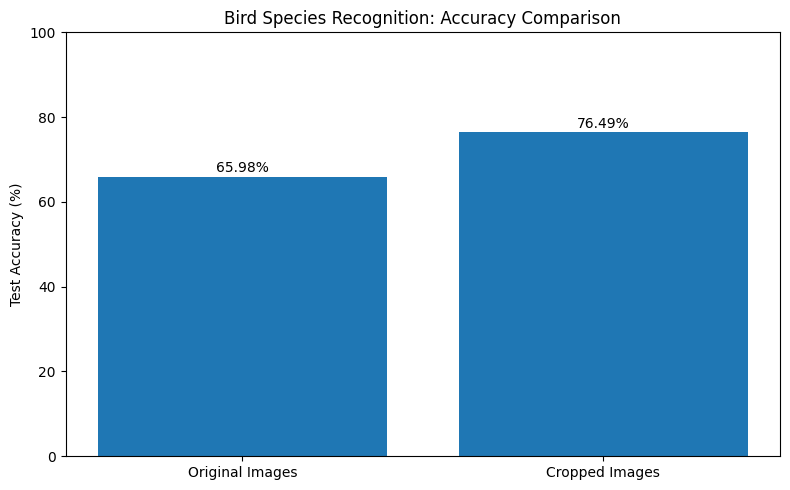

In [18]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Original Images", "Cropped Images"]
accuracy = [65.98, 76.49]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracy)

plt.title("Bird Species Recognition: Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("/content/accuracy_comparison.png", dpi=300)
plt.show()

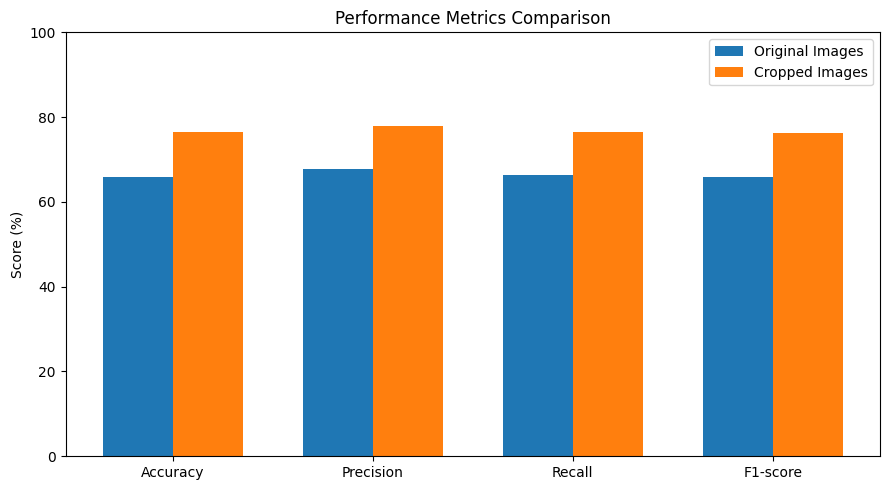

In [19]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
original = [65.98, 67.70, 66.27, 65.77]
cropped = [76.49, 77.91, 76.60, 76.21]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, original, width, label="Original Images")
plt.bar(x + width/2, cropped, width, label="Cropped Images")

plt.xticks(x, metrics)
plt.ylabel("Score (%)")
plt.title("Performance Metrics Comparison")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.savefig("/content/performance_metrics.png", dpi=300)
plt.show()

In [20]:
#Saving the graphs

from google.colab import files

files.download("/content/accuracy_comparison.png")
files.download("/content/performance_metrics.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Generate sample predictions**

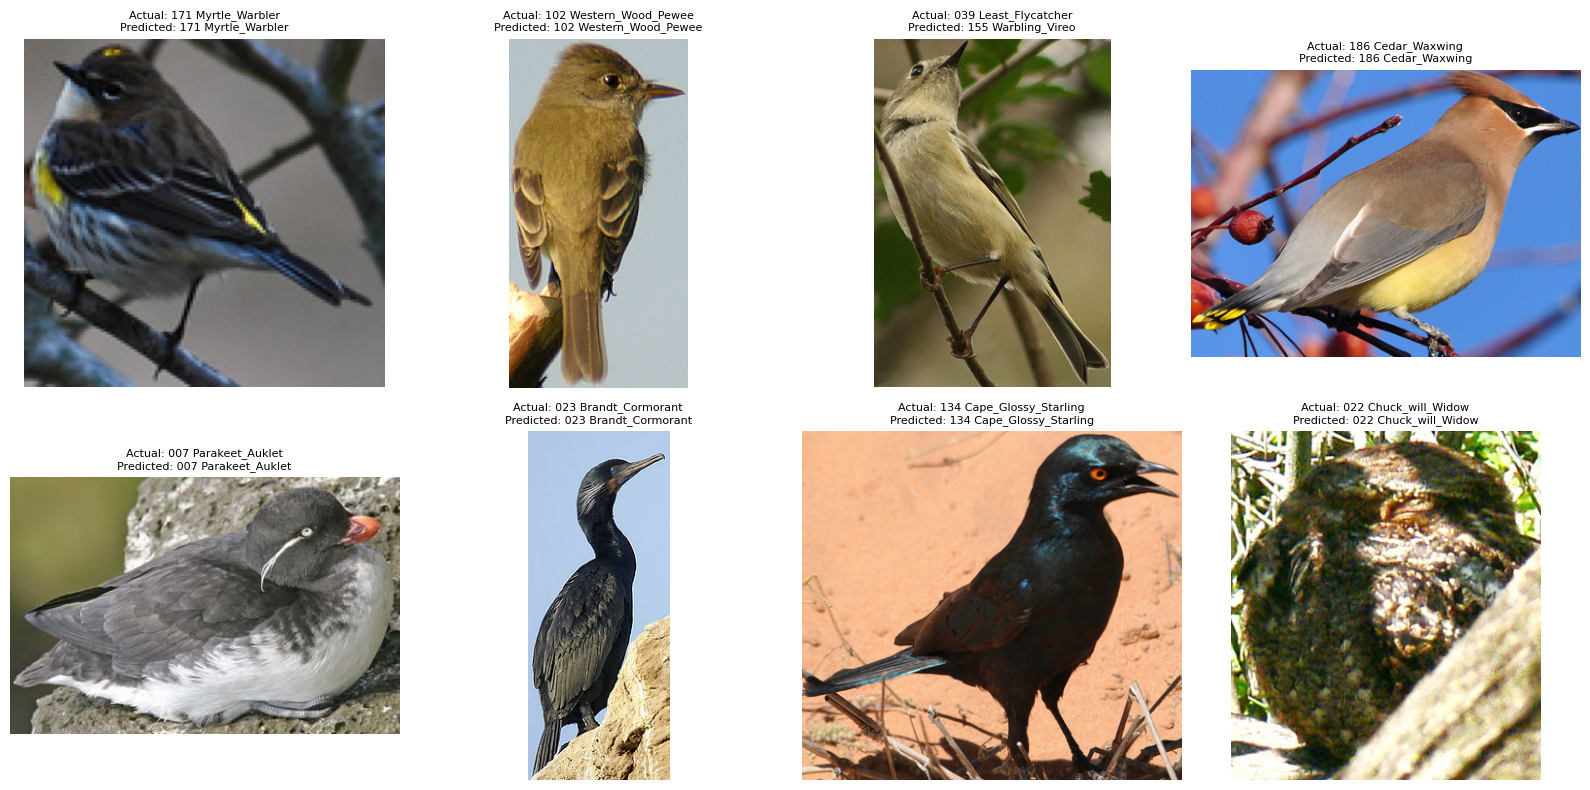

In [21]:
import matplotlib.pyplot as plt
import random
import torch
from PIL import Image

cropped_model.eval()

sample_df = test_df.sample(8, random_state=42).reset_index(drop=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

with torch.no_grad():
    for i, row in sample_df.iterrows():
        image = Image.open(row["filepath"]).convert("RGB")

        x = max(0, int(row["x"]))
        y = max(0, int(row["y"]))
        right = min(image.width, int(row["x"] + row["w"]))
        bottom = min(image.height, int(row["y"] + row["h"]))
        image = image.crop((x, y, right, bottom))

        tensor = eval_transform(image).unsqueeze(0).to(device)
        prediction = cropped_model(tensor).argmax(dim=1).item()

        true_name = df.loc[df["label"] == int(row["label"]), "filepath"].iloc[0]
        true_species = true_name.split("/")[-2].replace(".", " ")
        predicted_path = df.loc[df["label"] == prediction, "filepath"].iloc[0]
        predicted_species = predicted_path.split("/")[-2].replace(".", " ")

        axes.flat[i].imshow(image)
        axes.flat[i].set_title(
            f"Actual: {true_species}\nPredicted: {predicted_species}",
            fontsize=8
        )
        axes.flat[i].axis("off")

plt.tight_layout()
plt.savefig("/content/sample_predictions.png", dpi=300)
plt.show()

**Generate the classification report**

In [22]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

cropped_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in tqdm(cropped_test_loader, desc="Evaluating"):
        images = images.to(device)
        outputs = cropped_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions.tolist())
        y_true.extend(labels.numpy().tolist())

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(200)),
    target_names=[
        name.split("/")[-2].split(".", 1)[1]
        for name in df.sort_values("label")
            .drop_duplicates("label")["filepath"]
    ],
    zero_division=0
))

Evaluating:   0%|          | 0/182 [00:00<?, ?it/s]

                                precision    recall  f1-score   support

        Black_footed_Albatross       0.58      0.73      0.65        30
              Laysan_Albatross       0.84      0.70      0.76        30
               Sooty_Albatross       0.77      0.71      0.74        28
             Groove_billed_Ani       0.92      0.73      0.81        30
                Crested_Auklet       0.92      0.86      0.89        14
                  Least_Auklet       0.67      0.91      0.77        11
               Parakeet_Auklet       0.95      0.87      0.91        23
             Rhinoceros_Auklet       0.56      0.78      0.65        18
              Brewer_Blackbird       0.50      0.55      0.52        29
          Red_winged_Blackbird       0.94      0.97      0.95        30
               Rusty_Blackbird       0.52      0.47      0.49        30
       Yellow_headed_Blackbird       1.00      1.00      1.00        26
                      Bobolink       0.96      0.90      0.93  

**Plot the confusion matrix**

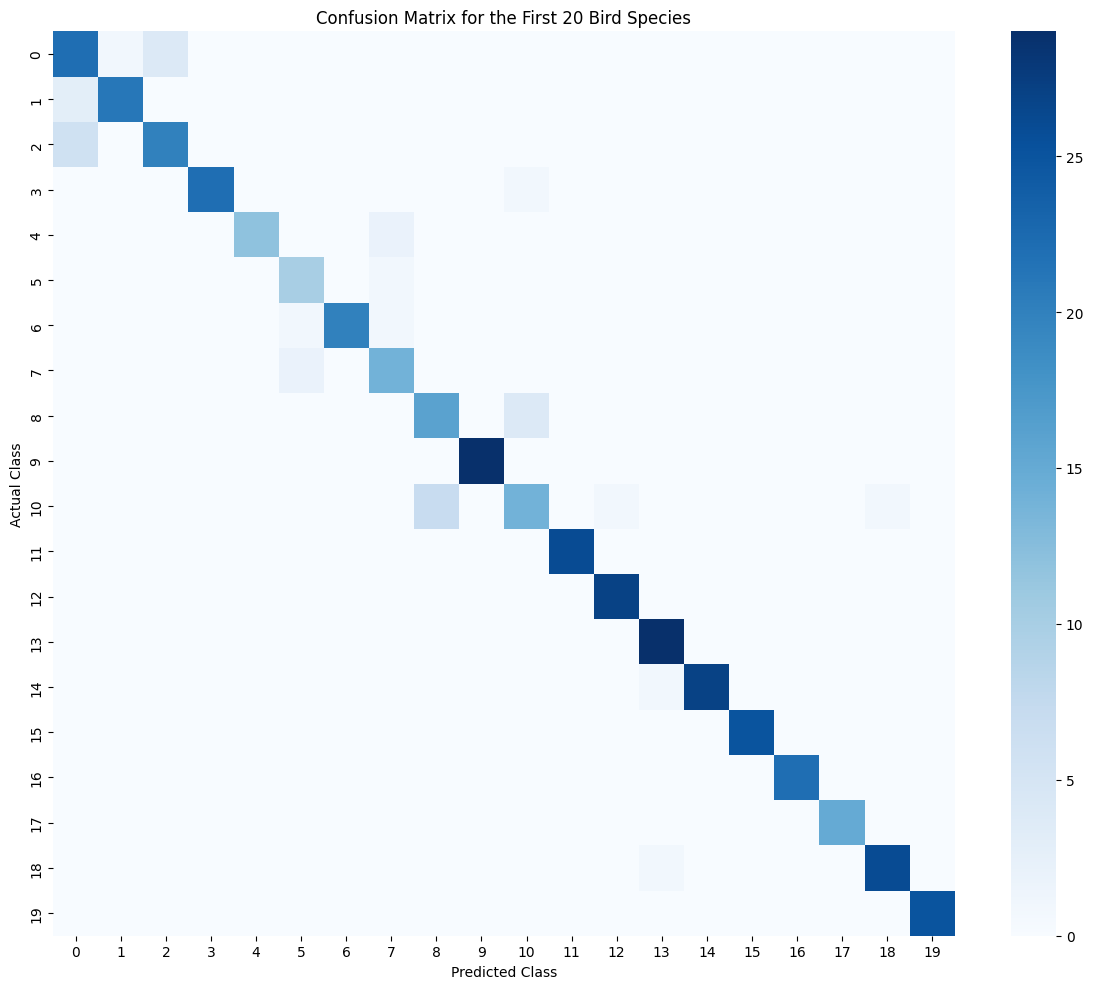

In [23]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(20)))

plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", annot=False, fmt="d")

plt.title("Confusion Matrix for the First 20 Bird Species")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig("/content/confusion_matrix.png", dpi=300)
plt.show()

In [24]:
from google.colab import files

files.download("/content/sample_predictions.png")
files.download("/content/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>